# Resume Screening System

This notebook is fully executed and saved with charts, model outputs, and project summary artifacts. The dataset is synthetic and intended for learning/portfolio practice.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, IsolationForest
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score
)
import joblib

pd.set_option("display.max_columns", None)
CHART_DIR = Path("charts")
CHART_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

## 2. NLP Workflow

Project: Resume Screening System
Dataset shape: (480, 3)


,text_id,text,category
0,124,aws azure docker kubernetes cloud deployment d...,Cloud
1,198,network security firewall linux threat vulnera...,Cyber Security
2,196,python machine learning pandas statistics mode...,Data Science
3,94,aws azure docker kubernetes cloud deployment d...,Cloud
4,132,html css javascript react node frontend backen...,Web Development


Text column: text | Target column: category


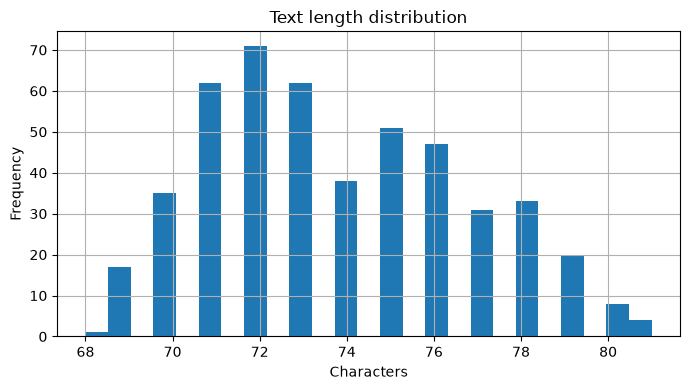

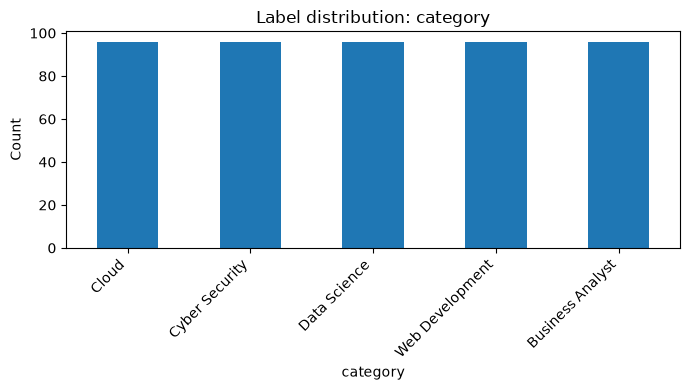

Accuracy: 1.0000
Precision_weighted: 1.0000
Recall_weighted: 1.0000
F1_weighted: 1.0000
                  precision    recall  f1-score   support

Business Analyst       1.00      1.00      1.00        19
           Cloud       1.00      1.00      1.00        19
  Cyber Security       1.00      1.00      1.00        19
    Data Science       1.00      1.00      1.00        20
 Web Development       1.00      1.00      1.00        19

        accuracy                           1.00        96
       macro avg       1.00      1.00      1.00        96
    weighted avg       1.00      1.00      1.00        96



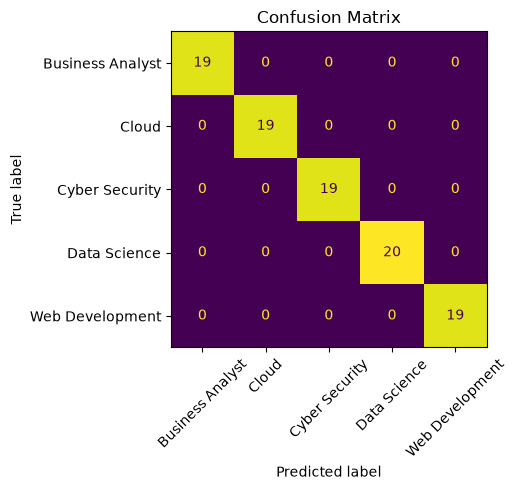

,term,importance
6,firewall,0.490170
5,firewall linux,0.490170
4,linux,0.490170
10,network security,0.490170
9,network,0.490170
8,security firewall,0.490170
7,security,0.490170
11,linux threat,0.490170
12,vulnerability,0.490170
13,threat vulnerability,0.490170


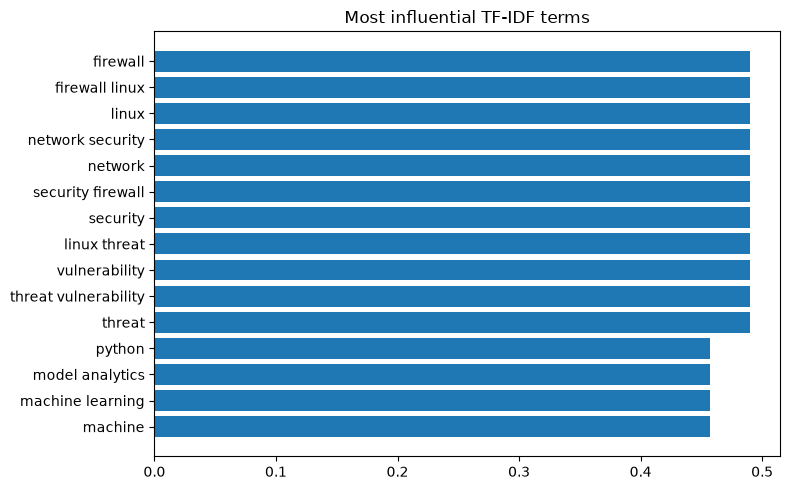

Saved project_summary.json


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
PROJECT_TITLE = 'Resume Screening System'
PROJECT_TYPE = 'NLP Classification'
DATA_FILE = 'text_dataset.csv'
TARGET_COLUMN = 'category'
LEVEL = 'Intermediate'
print(f"Project: {PROJECT_TITLE}")
df = pd.read_csv(DATA_FILE)
print("Dataset shape:", df.shape)
display(df.head())
text_col = "text" if "text" in df.columns else df.select_dtypes(include=["object"]).columns[0]
print("Text column:", text_col, "| Target column:", TARGET_COLUMN)
chart_paths=[]

df["text_length"] = df[text_col].astype(str).str.len()
plt.figure(figsize=(7,4))
df["text_length"].hist(bins=25)
plt.title("Text length distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")
plt.tight_layout()
path=CHART_DIR/"01_text_length_distribution.png"
plt.savefig(path,dpi=150,bbox_inches="tight")
chart_paths.append(str(path)); plt.show()

plt.figure(figsize=(7,4))
df[TARGET_COLUMN].astype(str).value_counts().plot(kind="bar")
plt.title(f"Label distribution: {TARGET_COLUMN}")
plt.xlabel(TARGET_COLUMN)
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
path=CHART_DIR/"02_label_distribution.png"
plt.savefig(path,dpi=150,bbox_inches="tight")
chart_paths.append(str(path)); plt.show()

X_train, X_test, y_train, y_test = train_test_split(df[text_col].astype(str), df[TARGET_COLUMN].astype(str), test_size=0.2, random_state=RANDOM_STATE, stratify=df[TARGET_COLUMN].astype(str))
model = Pipeline([("tfidf", TfidfVectorizer(stop_words="english", max_features=2500, ngram_range=(1,2))), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
model.fit(X_train, y_train)
pred = model.predict(X_test)
metrics={"Accuracy":float(accuracy_score(y_test,pred)),"Precision_weighted":float(precision_score(y_test,pred,average="weighted",zero_division=0)),"Recall_weighted":float(recall_score(y_test,pred,average="weighted",zero_division=0)),"F1_weighted":float(f1_score(y_test,pred,average="weighted",zero_division=0))}
for k,v in metrics.items(): print(f"{k}: {v:.4f}")
print(classification_report(y_test,pred,zero_division=0))
labels=sorted(pd.Series(y_test).unique())
cm=confusion_matrix(y_test,pred,labels=labels)
disp=ConfusionMatrixDisplay(cm,display_labels=labels)
fig, ax=plt.subplots(figsize=(7,5))
disp.plot(ax=ax,xticks_rotation=45,colorbar=False)
plt.title("Confusion Matrix")
plt.tight_layout()
path=CHART_DIR/"03_confusion_matrix.png"
plt.savefig(path,dpi=150,bbox_inches="tight")
chart_paths.append(str(path)); plt.show()

vectorizer=model.named_steps["tfidf"]
clf=model.named_steps["clf"]
terms=np.array(vectorizer.get_feature_names_out())
if hasattr(clf, "coef_"):
    weights=np.mean(np.abs(clf.coef_), axis=0) if clf.coef_.ndim > 1 else np.abs(clf.coef_[0])
    top_idx=np.argsort(weights)[-15:]
    top_terms=pd.DataFrame({"term": terms[top_idx], "importance": weights[top_idx]}).sort_values("importance", ascending=False)
    display(top_terms)
    plt.figure(figsize=(8,5))
    plt.barh(top_terms["term"][::-1], top_terms["importance"][::-1])
    plt.title("Most influential TF-IDF terms")
    plt.tight_layout()
    path=CHART_DIR/"04_top_text_features.png"
    plt.savefig(path,dpi=150,bbox_inches="tight")
    chart_paths.append(str(path)); plt.show()

summary_payload={"project_title":PROJECT_TITLE,"level":LEVEL,"project_type":PROJECT_TYPE,"task_kind":"nlp_classification","dataset_file":DATA_FILE,"dataset_shape":list(df.shape),"target_column":TARGET_COLUMN,"metrics":metrics,"charts":chart_paths,"generated_at":"2026-06-03"}
Path("project_summary.json").write_text(json.dumps(summary_payload, indent=2), encoding="utf-8")
print("Saved project_summary.json")

## Final Note

This project is complete for educational use: dataset, executed notebook, charts, PDF report, and documentation are included.